In [3]:
from sklearn.model_selection import cross_val_score
from sklearn.ensemble import RandomForestRegressor
from sklearn.linear_model import LinearRegression
from sklearn.metrics import f1_score
# import matplotlib.pyplot as plt

from sklearn.metrics import accuracy_score
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.model_selection import RandomizedSearchCV
from scipy.stats import randint
import json
import joblib
import pandas as pd
import time
from sklearn.model_selection import GridSearchCV
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline


In [4]:
df = pd.read_csv('car_price_prediction_.csv')

In [5]:
df.head(5)

,Car ID,Brand,Year,Engine Size,Fuel Type,Transmission,Mileage,Condition,Price,Model
0,1,Tesla,2016,2.3,Petrol,Manual,114832,New,26613.92,Model X
1,2,BMW,2018,4.4,Electric,Manual,143190,Used,14679.61,5 Series
2,3,Audi,2013,4.5,Electric,Manual,181601,New,44402.61,A4
3,4,Tesla,2011,4.1,Diesel,Automatic,68682,New,86374.33,Model Y
4,5,Ford,2009,2.6,Diesel,Manual,223009,Like New,73577.10,Mustang


In [6]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 2500 entries, 0 to 2499
Data columns (total 10 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   Car ID        2500 non-null   int64  
 1   Brand         2500 non-null   str    
 2   Year          2500 non-null   int64  
 3   Engine Size   2500 non-null   float64
 4   Fuel Type     2500 non-null   str    
 5   Transmission  2500 non-null   str    
 6   Mileage       2500 non-null   int64  
 7   Condition     2500 non-null   str    
 8   Price         2500 non-null   float64
 9   Model         2500 non-null   str    
dtypes: float64(2), int64(3), str(5)
memory usage: 195.4 KB


In [7]:
df.shape

(2500, 10)

In [8]:
df.describe()

,Car ID,Year,Engine Size,Mileage,Price
count,2500.00000,2500.0000,2500.000000,2500.000000,2500.000000
mean,1250.50000,2011.6268,3.465240,149749.844800,52638.022532
std,721.83216,6.9917,1.432053,87919.952034,27295.833455
min,1.00000,2000.0000,1.000000,15.000000,5011.270000
25%,625.75000,2005.0000,2.200000,71831.500000,28908.485000
50%,1250.50000,2012.0000,3.400000,149085.000000,53485.240000
75%,1875.25000,2018.0000,4.700000,225990.500000,75838.532500
max,2500.00000,2023.0000,6.000000,299967.000000,99982.590000


In [9]:
df.isnull().sum()

Car ID          0
Brand           0
Year            0
Engine Size     0
Fuel Type       0
Transmission    0
Mileage         0
Condition       0
Price           0
Model           0
dtype: int64

In [10]:
df.duplicated().sum()

np.int64(0)

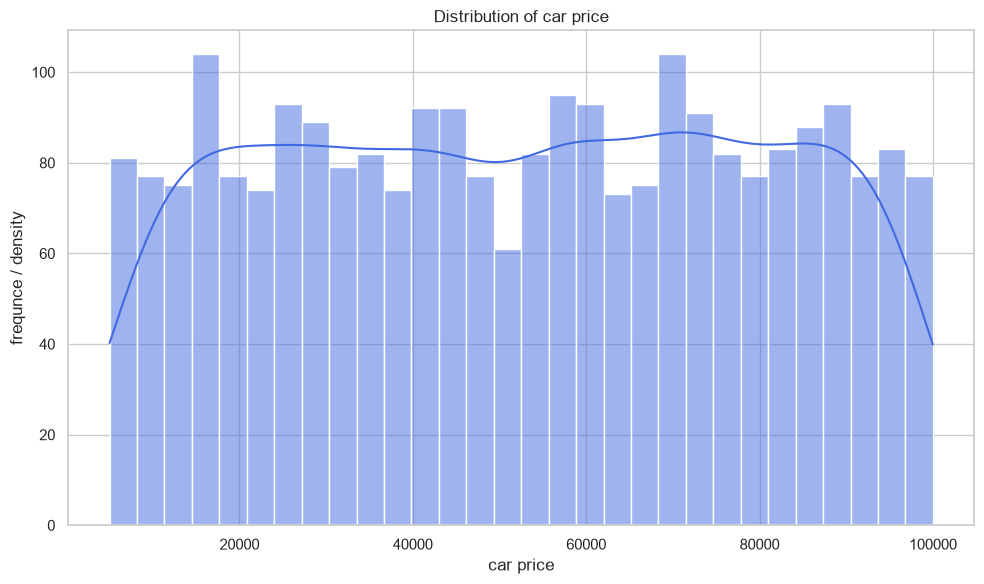

In [11]:
import seaborn as sns
import matplotlib.pyplot as plt

sns.set_theme(style = 'whitegrid')

plt.figure(figsize=(10, 6))

sns.histplot(
    data = df,
    x = 'Price',
    kde = True,
    bins = 30,
    color = 'royalblue'
)

plt.title('Distribution of car price')
plt.xlabel('car price')
plt.ylabel('frequnce / density')

plt.tight_layout()
plt.show()

In [12]:
df['Brand'].unique()

<StringArray>
['Tesla', 'BMW', 'Audi', 'Ford', 'Honda', 'Mercedes', 'Toyota']
Length: 7, dtype: str

In [13]:
df['Fuel Type'].unique()

<StringArray>
['Petrol', 'Electric', 'Diesel', 'Hybrid']
Length: 4, dtype: str

In [14]:
df['Model'].unique()

<StringArray>
[ 'Model X', '5 Series',       'A4',  'Model Y',  'Mustang',       'Q7',
       'Q5',    'Civic', 'Explorer',  'Model 3',   'Fiesta',       'X3',
      'GLA',       'A3',       'X5',  'C-Class',  'E-Class',     'CR-V',
    'Camry',   'Accord',      'GLC',  'Corolla',      'Fit',  'Model S',
    'Prius', '3 Series',     'RAV4',    'Focus']
Length: 28, dtype: str

In [15]:
df['Condition'].unique()

<StringArray>
['New', 'Used', 'Like New']
Length: 3, dtype: str

In [16]:
df['Transmission'].unique()

<StringArray>
['Manual', 'Automatic']
Length: 2, dtype: str

In [17]:
df['Condition'].value_counts()

Condition
Used        855
Like New    836
New         809
Name: count, dtype: int64

In [18]:
X = df.drop(['Price', 'Car ID'], axis= 1)
y = df['Price']

In [19]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size= 0.2, random_state= 42)

In [20]:
numeric_features = ['Year', 'Mileage', 'Engine Size'] # List of numeric features
categorical_features = ['Brand', 'Model', 'Condition', 'Transmission', 'Fuel Type'] # List of categorical features

In [21]:
num_transformer = Pipeline(steps = [
    ('scaler', StandardScaler()) # Standardize the numeric features
])

cat_transformer = Pipeline(steps = [
    ('onehot', OneHotEncoder(handle_unknown= 'ignore', drop = 'first')) # One-hot encode the categorical features
])

In [22]:
preprocessor = ColumnTransformer(transformers = [
    ('num', num_transformer, numeric_features),
    ('cat', cat_transformer, categorical_features)
])

In [23]:
base_model = Pipeline(steps = [
    ('preprocessor', preprocessor),
    ('regressor', RandomForestRegressor(random_state= 42))
])

In [24]:
base_model.fit(X_train, y_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocessor', ...), ('regressor', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](8,)","['Brand','Year','Engine Size',...,'Mileage','Condition','Model']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,8
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('cat', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsis co

In [25]:
base_predictions = base_model.predict(X_test)

In [26]:
base_predictions

array([62811.4661, 43723.0584, 50351.5537, 51752.6938, 48770.2112,
       45303.5288, 54444.9928, 47446.5779, 57775.0291, 54832.934 ,
       60226.7539, 33964.3462, 59728.0145, 45860.7247, 44539.4457,
       44587.5099, 56515.5782, 61560.1057, 49276.2789, 56114.6629,
       57403.2901, 42128.2458, 49801.1994, 45644.6841, 46976.376 ,
       57287.7405, 62023.7693, 56935.4801, 40654.4239, 57412.7652,
       51026.6991, 43570.7736, 49587.7145, 45478.7523, 38540.7702,
       46247.4541, 46210.505 , 33322.2859, 58419.1027, 36178.0042,
       57131.7099, 46275.5585, 53146.2995, 50268.8523, 48094.6755,
       39659.6175, 46918.007 , 65726.5722, 47104.8973, 54842.9167,
       45601.4085, 49023.5851, 60455.0282, 58328.5025, 46655.2627,
       37812.8579, 52721.4849, 53257.2447, 53382.3363, 49060.8315,
       55328.0158, 50254.2241, 41171.8916, 34007.8253, 51034.7093,
       54403.2727, 68576.731 , 59684.8745, 51839.4144, 50280.8766,
       52886.226 , 59108.1907, 51612.5715, 39109.6154, 62174.8

In [27]:
from sklearn.metrics import mean_squared_error, r2_score, mean_absolute_error, make_scorer
mse = mean_squared_error(y_test, base_predictions)
r2 = r2_score(y_test, base_predictions)
mae = mean_absolute_error(y_test, base_predictions) 
print(f'Mean Squared Error: {mse}')
print(f'R-squared: {r2}')
print(f'Mean Absolute Error: {mae}')

Mean Squared Error: 809934143.0635262
R-squared: -0.06914471700848956
Mean Absolute Error: 24579.8634166


In [29]:
scorer = make_scorer(mean_squared_error, greater_is_better=False)

scores = cross_val_score(base_model, X, y, cv=5, scoring=scorer)

print(f"Mean RMSE: {scores.mean():.2f} ± {scores.std():.2f}")

Mean RMSE: -798730852.37 ± 41476795.47
